### Data wrangling without loss

Inspect the “patients_lab_results_messy.csv” dataset

What is wrong with the dataset? Look for e.g. 
- Inconsistent labelling
- Inconsistent casing
- Missing values

Fix the issues without loosing any data! 

Discuss the reversibility of your steps and think about how you can make sure that you did not loose any data!


In [1]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("patients_results_messy.csv")
df

,Patient_ID,Visit Date,age,Gender,Blood Pressure (mmHg),Chol (mg_dl),glucose,Notes
0,P001,2021-01-03,34.0,Male,120/80,180.0,95,baseline
1,P002,2021/1/05,45.0,FEMALE,135/90,210.0,NaN,-
2,P003,03-01-2021,29.0,male,115/75,190.0,88,recheck
3,p004,2021.01.04,52.0,F,140/95,220.0,missing,new patient
4,P005,2021-01-06,33.0,M,118/78,185.0,89,repeat
5,P006,2021-01-06,33.0,M,118/78,185.0,89,repeat
6,P007,2021/01/07,NaN,Male,125/82,200.0,ninety,typo in glucose
7,P008,2021-01-08,46.0,Female,130/85,195.0,100,baseline
8,P009,2021-01-09,50.0,female,128/84,NaN,92,-
9,P010,2021-01-10,41.0,MALE,132/88,210.0,97,follow-up


Clean up column names using string methods:

In [2]:
df.columns = df.columns.str.lower().str.replace('[^a-z0-9]+', '_', regex=True).str.strip('_')
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes
0,P001,2021-01-03,34.0,Male,120/80,180.0,95,baseline
1,P002,2021/1/05,45.0,FEMALE,135/90,210.0,NaN,-
2,P003,03-01-2021,29.0,male,115/75,190.0,88,recheck
3,p004,2021.01.04,52.0,F,140/95,220.0,missing,new patient
4,P005,2021-01-06,33.0,M,118/78,185.0,89,repeat
5,P006,2021-01-06,33.0,M,118/78,185.0,89,repeat
6,P007,2021/01/07,NaN,Male,125/82,200.0,ninety,typo in glucose
7,P008,2021-01-08,46.0,Female,130/85,195.0,100,baseline
8,P009,2021-01-09,50.0,female,128/84,NaN,92,-
9,P010,2021-01-10,41.0,MALE,132/88,210.0,97,follow-up


Split blood pressure values into two columns, using the string method split():

In [3]:
df[['systolic', 'diastolic']] = df['blood_pressure_mmhg'].str.split('/', expand=True)
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic
0,P001,2021-01-03,34.0,Male,120/80,180.0,95,baseline,120,80
1,P002,2021/1/05,45.0,FEMALE,135/90,210.0,NaN,-,135,90
2,P003,03-01-2021,29.0,male,115/75,190.0,88,recheck,115,75
3,p004,2021.01.04,52.0,F,140/95,220.0,missing,new patient,140,95
4,P005,2021-01-06,33.0,M,118/78,185.0,89,repeat,118,78
5,P006,2021-01-06,33.0,M,118/78,185.0,89,repeat,118,78
6,P007,2021/01/07,NaN,Male,125/82,200.0,ninety,typo in glucose,125,82
7,P008,2021-01-08,46.0,Female,130/85,195.0,100,baseline,130,85
8,P009,2021-01-09,50.0,female,128/84,NaN,92,-,128,84
9,P010,2021-01-10,41.0,MALE,132/88,210.0,97,follow-up,132,88


In [4]:
df.systolic = df.systolic.apply(pd.to_numeric)
df.diastolic = df.diastolic.apply(pd.to_numeric)
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic
0,P001,2021-01-03,34.0,Male,120/80,180.0,95,baseline,120,80
1,P002,2021/1/05,45.0,FEMALE,135/90,210.0,NaN,-,135,90
2,P003,03-01-2021,29.0,male,115/75,190.0,88,recheck,115,75
3,p004,2021.01.04,52.0,F,140/95,220.0,missing,new patient,140,95
4,P005,2021-01-06,33.0,M,118/78,185.0,89,repeat,118,78
5,P006,2021-01-06,33.0,M,118/78,185.0,89,repeat,118,78
6,P007,2021/01/07,NaN,Male,125/82,200.0,ninety,typo in glucose,125,82
7,P008,2021-01-08,46.0,Female,130/85,195.0,100,baseline,130,85
8,P009,2021-01-09,50.0,female,128/84,NaN,92,-,128,84
9,P010,2021-01-10,41.0,MALE,132/88,210.0,97,follow-up,132,88


Convert glucose values:

In [5]:
df['glucose'] = pd.to_numeric(df['glucose'], errors="coerce") # avoids crashing if wrong types are parsed
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic
0,P001,2021-01-03,34.0,Male,120/80,180.0,95.0,baseline,120,80
1,P002,2021/1/05,45.0,FEMALE,135/90,210.0,NaN,-,135,90
2,P003,03-01-2021,29.0,male,115/75,190.0,88.0,recheck,115,75
3,p004,2021.01.04,52.0,F,140/95,220.0,NaN,new patient,140,95
4,P005,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78
5,P006,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78
6,P007,2021/01/07,NaN,Male,125/82,200.0,NaN,typo in glucose,125,82
7,P008,2021-01-08,46.0,Female,130/85,195.0,100.0,baseline,130,85
8,P009,2021-01-09,50.0,female,128/84,NaN,92.0,-,128,84
9,P010,2021-01-10,41.0,MALE,132/88,210.0,97.0,follow-up,132,88


Standardize gender:

In [6]:
df['gender'] = df['gender'].str.upper().map({'MALE': 'M', 'FEMALE': 'F', 'M': 'M', 'F': 'F'})
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic
0,P001,2021-01-03,34.0,M,120/80,180.0,95.0,baseline,120,80
1,P002,2021/1/05,45.0,F,135/90,210.0,NaN,-,135,90
2,P003,03-01-2021,29.0,M,115/75,190.0,88.0,recheck,115,75
3,p004,2021.01.04,52.0,F,140/95,220.0,NaN,new patient,140,95
4,P005,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78
5,P006,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78
6,P007,2021/01/07,NaN,M,125/82,200.0,NaN,typo in glucose,125,82
7,P008,2021-01-08,46.0,F,130/85,195.0,100.0,baseline,130,85
8,P009,2021-01-09,50.0,F,128/84,NaN,92.0,-,128,84
9,P010,2021-01-10,41.0,M,132/88,210.0,97.0,follow-up,132,88


Parse dates to standard format:

In [7]:
# standardize visit_date
df['visit_date'] = (
    df['visit_date']
    .str.replace(r'[./]', '-', regex=True)  # unify separators
    .str.strip()
)

df['visit_date_clean'] = pd.to_datetime(df['visit_date'], format='mixed')
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic,visit_date_clean
0,P001,2021-01-03,34.0,M,120/80,180.0,95.0,baseline,120,80,2021-01-03
1,P002,2021-1-05,45.0,F,135/90,210.0,NaN,-,135,90,2021-01-05
2,P003,03-01-2021,29.0,M,115/75,190.0,88.0,recheck,115,75,2021-03-01
3,p004,2021-01-04,52.0,F,140/95,220.0,NaN,new patient,140,95,2021-01-04
4,P005,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78,2021-01-06
5,P006,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78,2021-01-06
6,P007,2021-01-07,NaN,M,125/82,200.0,NaN,typo in glucose,125,82,2021-01-07
7,P008,2021-01-08,46.0,F,130/85,195.0,100.0,baseline,130,85,2021-01-08
8,P009,2021-01-09,50.0,F,128/84,NaN,92.0,-,128,84,2021-01-09
9,P010,2021-01-10,41.0,M,132/88,210.0,97.0,follow-up,132,88,2021-01-10


Further cleanup: patient_id!

In [8]:
df.patient_id = df.patient_id.str.upper()
df

,patient_id,visit_date,age,gender,blood_pressure_mmhg,chol_mg_dl,glucose,notes,systolic,diastolic,visit_date_clean
0,P001,2021-01-03,34.0,M,120/80,180.0,95.0,baseline,120,80,2021-01-03
1,P002,2021-1-05,45.0,F,135/90,210.0,NaN,-,135,90,2021-01-05
2,P003,03-01-2021,29.0,M,115/75,190.0,88.0,recheck,115,75,2021-03-01
3,P004,2021-01-04,52.0,F,140/95,220.0,NaN,new patient,140,95,2021-01-04
4,P005,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78,2021-01-06
5,P006,2021-01-06,33.0,M,118/78,185.0,89.0,repeat,118,78,2021-01-06
6,P007,2021-01-07,NaN,M,125/82,200.0,NaN,typo in glucose,125,82,2021-01-07
7,P008,2021-01-08,46.0,F,130/85,195.0,100.0,baseline,130,85,2021-01-08
8,P009,2021-01-09,50.0,F,128/84,NaN,92.0,-,128,84,2021-01-09
9,P010,2021-01-10,41.0,M,132/88,210.0,97.0,follow-up,132,88,2021-01-10


### Concatenation and merging of dataframes

Add the extended patient list and the patients info to your cleaned up dataframe. Inspect the shape of the dataframes after each operation.

In [9]:
df_extension = pd.read_csv("patient_list_extended.csv")
df_2merge = pd.read_csv("patients_info.csv")

1) Concatenation. Try different options, e.g. `axis=`

In [12]:
df_extended = pd.concat([df,df_extension], ignore_index=True)
df_extended.shape

(52, 11)

2) Merging. Play with different modes (`how=`)

In [13]:
df_complete = pd.merge(df_extended, df_2merge, on="patient_id", how="outer")
df_complete.shape

(56, 13)

`join()` can be used to the same purpose, but requires an index to do so:

In [14]:
df_complete2 = df_extended.join(df_2merge.set_index("patient_id"), on="patient_id", how="outer")
df_complete2.shape

(56, 13)

Write to a csv.

In [15]:
df_complete.to_csv("patients_list_complete.csv",index=False)

### Data wrangling with loss

Intentional loss / deletion of data always needs to be documented / commented. In this notebook this is only done in a very minimalistic version for brevity.

Assess the `NaN` in your combined dataframe.

Flag missing values, e.g. for age or glucose values.

Drop rows where a defined column, e.g. glucose, contains an `NaN`.

Assess duplicates. Assess partial duplicates using `subset=`. Delete if needed.

### Outlier filtering

Use the glucose as an example feature to practice outlier assessment. Check in a plot how the pattern is affected by the changes.

The classic: Innerquartile range (see Box plot)

<Axes: ylabel='glucose'>

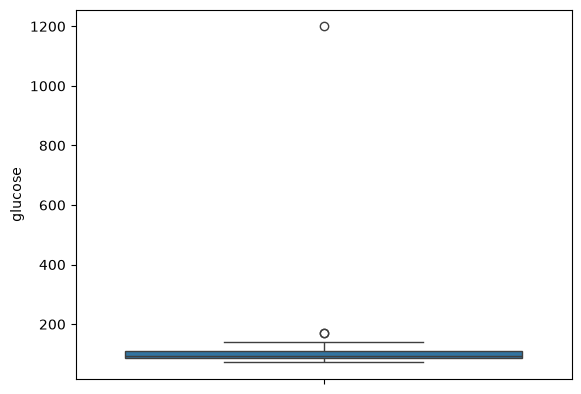

In [16]:
sns.boxplot(df_complete.glucose)

Filter as to whatever lies within the IQR.

In [17]:
# IQR
Q1 = df_complete.glucose.quantile(0.25)
Q3 = df_complete.glucose.quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

print(Q1, Q3)

85.0 111.0


In [18]:
filtered_df = df[(df_complete.glucose >= lower) & (df_complete.glucose <= upper)]
filtered_df.shape

C:\Users\jschoer\AppData\Local\Temp\ipykernel_49236\1734764132.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered_df = df[(df_complete.glucose >= lower) & (df_complete.glucose <= upper)]


(7, 11)

<Axes: xlabel='glucose', ylabel='Count'>

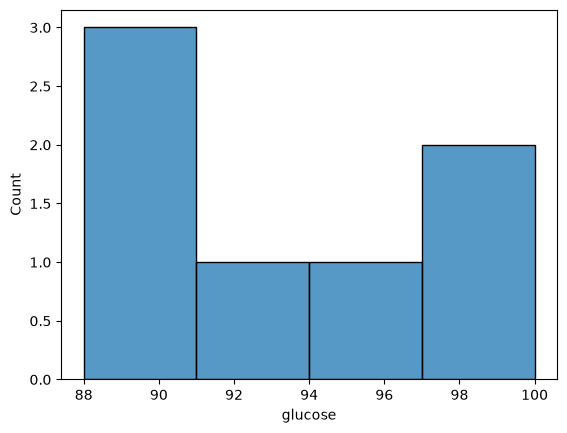

In [19]:
sns.histplot(filtered_df.glucose)

<Axes: xlabel='glucose', ylabel='Count'>

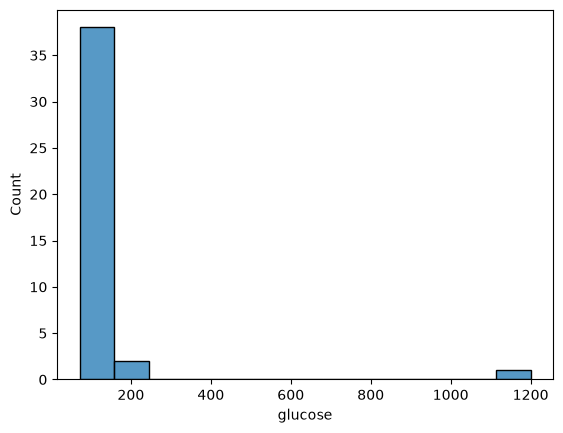

In [20]:
sns.histplot(df_complete.glucose)

Clip the data at a certain quantile, using the ``clip`` method.

In [21]:
lower = df_complete.chol_mg_dl.quantile(0.02)
upper = df_complete.chol_mg_dl.quantile(0.98)

clipped_df = df_complete.chol_mg_dl.clip(lower, upper)
clipped_df.head()


0    180.0
1    210.0
2    190.0
3    220.0
4    185.0
Name: chol_mg_dl, dtype: float64

Other outlier assessment exist, e.g. z-scores. A point is considered an outlier if its z-score is lower than -3 or higher than 3 (i.e. is further away from the mean than three standard deviations)

In [22]:
from scipy import stats
# zscore fails if NaNs are not removed, use a df where missing values for glucose are removed
df_dropna_glu = df_complete.dropna(subset=["glucose"])
filtered_df2 = df_dropna_glu[abs(stats.zscore(df_dropna_glu.glucose)) < 3] 
filtered_df2.shape

(40, 13)